# 03 xs relative strength

Validation backtest for this trading module. The tape is synthetic and seeded, so the chart checks that the production rules fire and how the book compounds after 10 bps a side. It is not a live-edge claim.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT.name and not (ROOT / "pipeline").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pipeline.research.validation.figures import draw_module, metrics_frame
from pipeline.research.validation.modules import run_module
from pipeline.research.validation.panel import synthetic_panel

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)


In [2]:
panel = synthetic_panel()
result = run_module('xs', panel)
print(result.title)
for rule in result.rules:
    print("-", rule)
print()
print(result.note)
metrics_frame(result)


XS sleeve — sector residual strength
- Score is the 63-session return minus the equal-weight return of the same sector.
- A one-name sector is dropped. There is no peer to be relative to.
- Hold the top 8, at most 2 per sector, and rebalance every 5 sessions.
- A down close is not an exit. The sleeve leaves a name when it falls out of the basket.

Synthetic tape, seeded. Paper costs of 10 bps a side. Not a live-edge claim.


,days,total_return_pct,cagr_pct,sharpe,max_drawdown_pct,n_trades,win_rate_pct,avg_trade_pct
0,420,52.47,28.8,3.11,-3.03,70,67.14,0.611


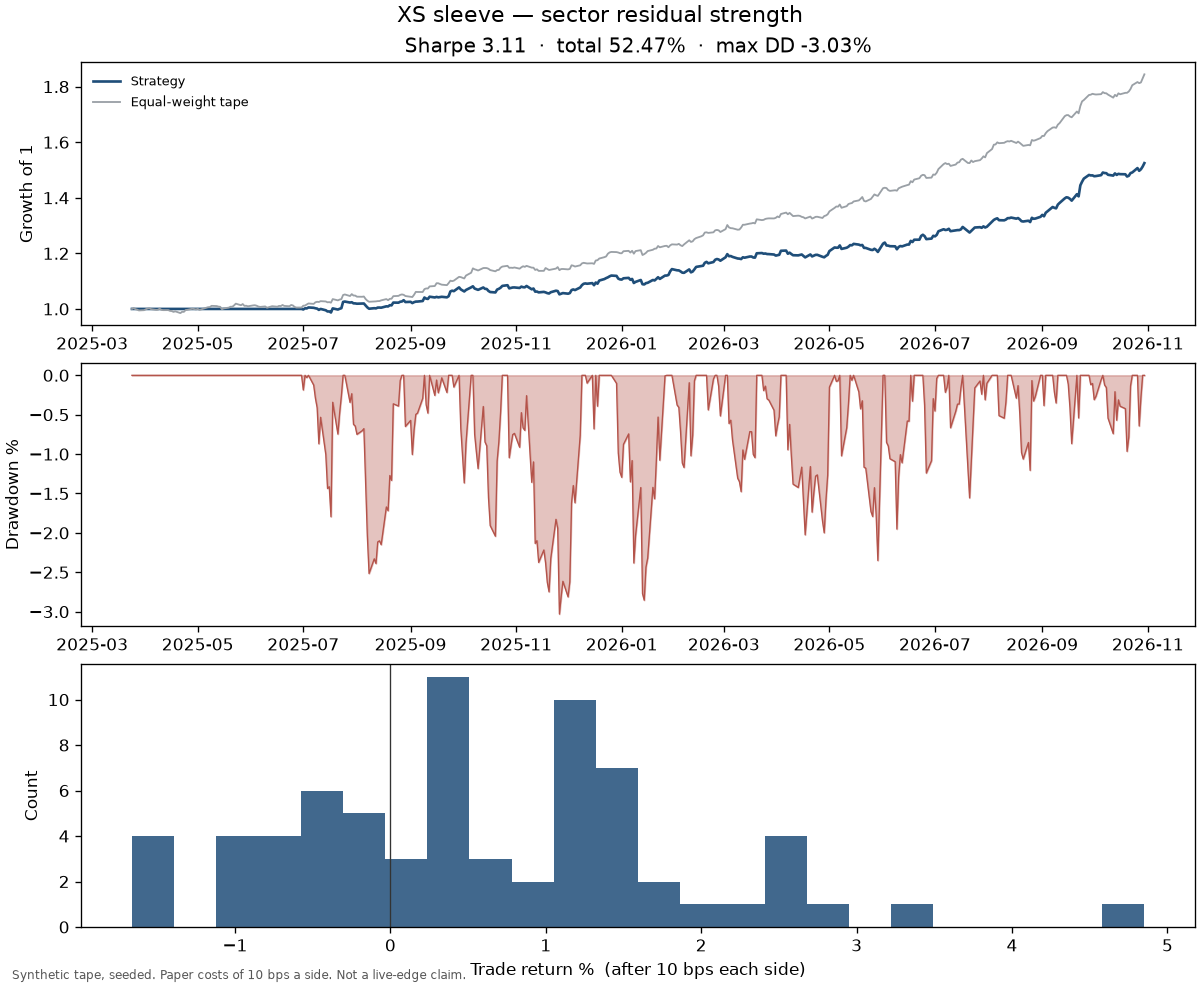

In [3]:
from IPython.display import Image, display

fig_dir = ROOT / "pipeline" / "research" / "notebooks" / "validation" / "figures"
fig_path = fig_dir / "03_xs_relative_strength.png"
fig = draw_module(result, fig_path)
plt.close(fig)
display(Image(filename=str(fig_path)))
